# 5. Fourier Transform and Sampling

Practice for module 5: Fourier pairs checked numerically, the convolution theorem, magnitude vs phase,
low/high/band-pass filtering, why some blurs cannot be inverted, Wiener deconvolution, and aliasing
(including the square wave, which always aliases) with pixel-area averaging as an anti-aliasing filter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

def make_image(n=128, seed=0):
    r = np.random.default_rng(seed)
    y, x = np.mgrid[:n, :n] / n
    img = 0.3 + 0.3 * x
    for _ in range(6):
        cx, cy, rad = r.uniform(0.15, 0.85, 2).tolist() + [r.uniform(0.05, 0.15)]
        img[(x - cx) ** 2 + (y - cy) ** 2 < rad ** 2] = r.uniform(0, 1)
    return img

def psnr(a, b):
    return 10 * np.log10(1 / np.mean((a - b) ** 2))

## 5.1 Fourier pairs

Box ↔ sinc, triangle ↔ sinc², Gaussian ↔ Gaussian, impulse ↔ constant, sinusoid ↔ two impulses.
Also the scaling property: stretching a Gaussian in space narrows its spectrum.

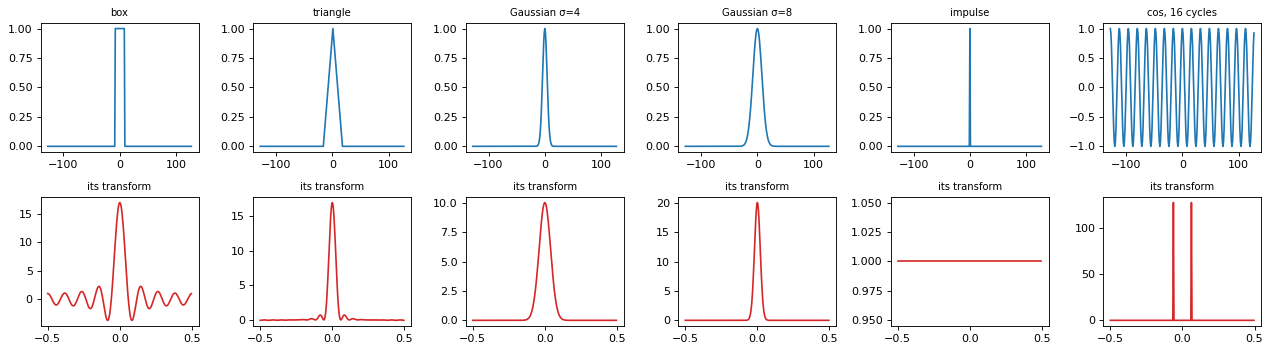

box transform matches the sinc formula: True


In [2]:
N = 256; x = np.arange(N) - N // 2; u = np.fft.fftshift(np.fft.fftfreq(N))
box = (np.abs(x) <= 8).astype(float)
tri = np.convolve(box, box, "same") / box.sum()
signals = {"box": box, "triangle": tri, "Gaussian σ=4": np.exp(-x ** 2 / 32), "Gaussian σ=8": np.exp(-x ** 2 / 128),
           "impulse": (x == 0).astype(float), "cos, 16 cycles": np.cos(2 * np.pi * 16 * x / N)}
fig, axes = plt.subplots(2, 6, figsize=(16, 4.5))
for j, (name, s) in enumerate(signals.items()):
    F = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(s))).real
    axes[0, j].plot(x, s); axes[0, j].set_title(name, fontsize=9)
    axes[1, j].plot(u, F, "tab:red"); axes[1, j].set_title("its transform", fontsize=9)
plt.tight_layout(); plt.show()
s = 17; Fb = np.fft.fft(np.fft.ifftshift(box)).real
print("box transform matches the sinc formula:", np.allclose(Fb, [s if k == 0 else np.sin(np.pi * k * s / N) / np.sin(np.pi * k / N) for k in range(N)]))

## 5.2 Convolution theorem

In [3]:
img = make_image()
k = np.zeros_like(img); k[:5, :5] = 1 / 25; k = np.roll(k, (-2, -2), (0, 1))
direct = sum(np.roll(np.roll(img, dy, 0), dx, 1) for dy in range(-2, 3) for dx in range(-2, 3)) / 25
via_fft = np.fft.ifft2(np.fft.fft2(img) * np.fft.fft2(k)).real
print("circular 5x5 box blur: direct vs FFT, max diff", f"{np.abs(direct - via_fft).max():.1e}")

circular 5x5 box blur: direct vs FFT, max diff 5.6e-16


## 5.3 Magnitude vs phase

Swap the Fourier phases of two images. Each hybrid looks like the image that gave its phase: the phase
holds where the edges are, the magnitude mostly holds the overall energy per frequency.

|A| with phase of B: corr with A 0.15, with B 0.82
|B| with phase of A: corr with A 0.82, with B 0.21


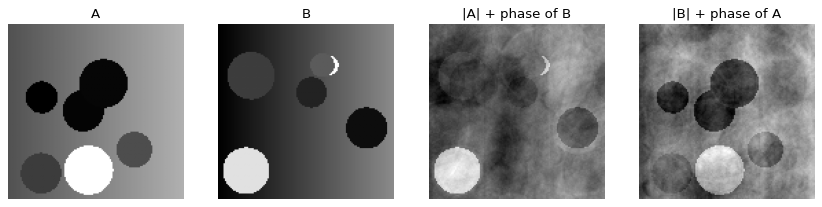

In [4]:
a, b = make_image(seed=5), make_image(seed=6)
a, b = a - a.mean(), b - b.mean()
Fa, Fb2 = np.fft.fft2(a), np.fft.fft2(b)
ab = np.fft.ifft2(np.abs(Fa) * np.exp(1j * np.angle(Fb2))).real
ba = np.fft.ifft2(np.abs(Fb2) * np.exp(1j * np.angle(Fa))).real
corr = lambda p, q: np.corrcoef(p.ravel(), q.ravel())[0, 1]
print(f"|A| with phase of B: corr with A {corr(ab, a):.2f}, with B {corr(ab, b):.2f}")
print(f"|B| with phase of A: corr with A {corr(ba, a):.2f}, with B {corr(ba, b):.2f}")
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, im, t in zip(axes, [a, b, ab, ba], ["A", "B", "|A| + phase of B", "|B| + phase of A"]):
    ax.imshow(im, cmap="gray"); ax.set_title(t); ax.axis("off")
plt.show()

## 5.4 Low-, high- and band-pass filtering

Ideal radial masks in frequency on a noisy image. Low pass blurs, high pass keeps edges and noise, band pass
keeps the edges while dropping the finest (noisiest) frequencies.

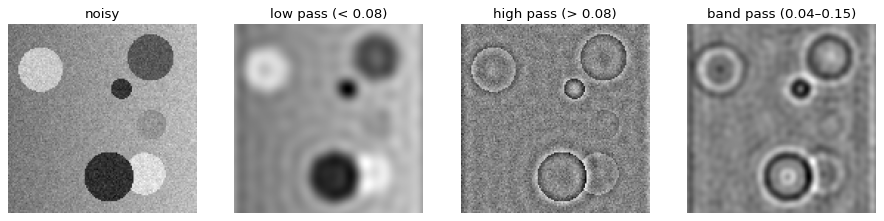

In [5]:
noisy = img + rng.normal(0, 0.05, img.shape)
fy, fx = np.meshgrid(np.fft.fftfreq(128), np.fft.fftfreq(128), indexing="ij")
rad = np.hypot(fx, fy)
F = np.fft.fft2(noisy)
masks = {"low pass (< 0.08)": rad < 0.08, "high pass (> 0.08)": rad > 0.08, "band pass (0.04–0.15)": (rad > 0.04) & (rad < 0.15)}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
axes[0].imshow(noisy, cmap="gray"); axes[0].set_title("noisy")
for a, (t, m) in zip(axes[1:], masks.items()):
    a.imshow(np.fft.ifft2(F * m).real, cmap="gray"); a.set_title(t)
for a in axes: a.axis("off")
plt.show()

## 5.5 Non-invertible blur and Wiener deconvolution

A 7-pixel horizontal box blur has a sinc-like transform with exact zeros: those frequencies are gone and no
filter can bring them back. The naive inverse divides noise by near-zero values. Wiener deconvolution
`H* / (|H|² + K)` inverts where the signal is strong and gives up where noise dominates.

smallest |H| along the horizontal frequency axis: 3.6e-03 (zeros at multiples of 1/7)


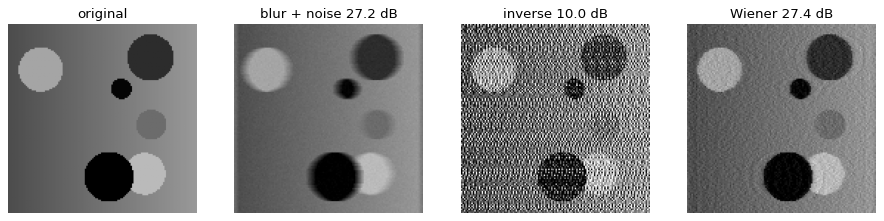

In [6]:
psf = np.zeros((128, 128)); psf[0, :7] = 1 / 7; psf = np.roll(psf, -3, 1)
H = np.fft.fft2(psf)
print(f"smallest |H| along the horizontal frequency axis: {np.abs(H[0]).min():.1e} (zeros at multiples of 1/7)")
g = np.fft.ifft2(np.fft.fft2(img) * H).real + rng.normal(0, 0.01, img.shape)
G = np.fft.fft2(g)
inv = np.fft.ifft2(G / np.where(np.abs(H) < 1e-3, 1e-3, H)).real
wien = np.fft.ifft2(np.conj(H) / (np.abs(H) ** 2 + 0.01) * G).real
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, im, t in zip(axes, [img, g, inv, wien], ["original", f"blur + noise {psnr(g, img):.1f} dB",
                                                   f"inverse {psnr(inv.clip(0, 1), img):.1f} dB", f"Wiener {psnr(wien.clip(0, 1), img):.1f} dB"]):
    ax.imshow(im.clip(0, 1), cmap="gray", vmin=0, vmax=1); ax.set_title(t); ax.axis("off")
plt.show()

## 5.6 Sampling and aliasing

Nyquist: sample at `f_s ≥ 2·u_max`. A 9 Hz sine sampled at 12 Hz looks like a 3 Hz sine. A square wave has
harmonics at every odd multiple, so it is never band-limited and always aliases. Sensors fight this by
averaging over the pixel area (a box filter) and with an optical low-pass filter.

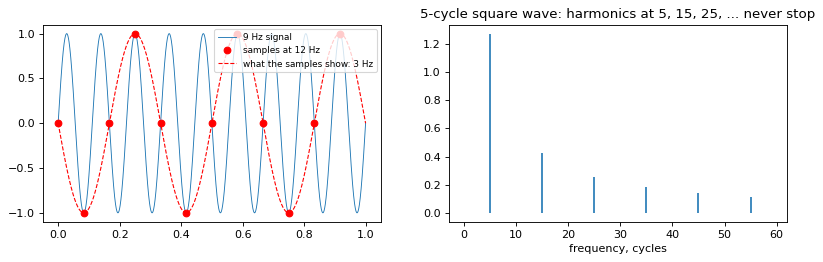

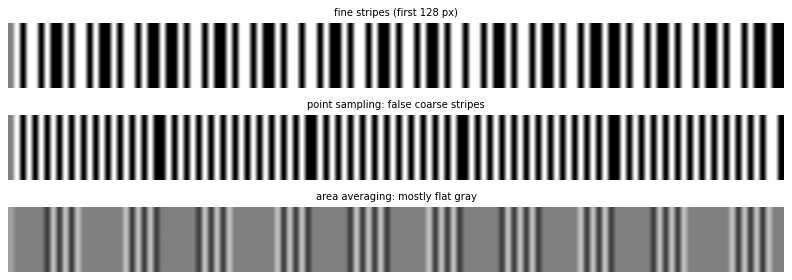

contrast of the aliased pattern: point sampling 0.498, area averaging 0.176


In [7]:
t = np.linspace(0, 1, 2000)
ts = np.arange(0, 1, 1 / 12)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].plot(t, np.sin(2 * np.pi * 9 * t), lw=0.8, label="9 Hz signal")
axes[0].plot(ts, np.sin(2 * np.pi * 9 * ts), "ro", label="samples at 12 Hz")
axes[0].plot(t, -np.sin(2 * np.pi * 3 * t), "r--", lw=1, label="what the samples show: 3 Hz")
axes[0].legend(fontsize=8, loc="upper right")
sq = np.sign(np.sin(2 * np.pi * 5 * np.arange(4096) / 4096))
spec = np.abs(np.fft.rfft(sq)) / 2048
axes[1].stem(np.arange(60), spec[:60], markerfmt=" ", basefmt=" "); axes[1].set_xlabel("frequency, cycles")
axes[1].set_title("5-cycle square wave: harmonics at 5, 15, 25, ... never stop")
plt.show()

fine = 0.5 + 0.5 * np.sign(np.sin(2 * np.pi * 0.37 * np.arange(512)))[None].repeat(64, 0)     # period 2.7 px
point = fine[:, ::4]                                   # point sampling every 4 px
area = fine.reshape(64, 128, 4).mean(-1)               # pixel-area averaging over 4 px
fig, axes = plt.subplots(3, 1, figsize=(10, 3.6))
for a, u_, ttl in zip(axes, [fine[:, :128], point, area], ["fine stripes (first 128 px)", "point sampling: false coarse stripes", "area averaging: mostly flat gray"]):
    a.imshow(u_, cmap="gray", aspect="auto", vmin=0, vmax=1); a.set_title(ttl, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()
print(f"contrast of the aliased pattern: point sampling {point.std():.3f}, area averaging {area.std():.3f}")